# Análise de nomeações e exonerações

In [1]:
import re
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

ARQ_NOMEADOS = "nomes_nomeados.csv"
ARQ_EXONERADOS = "nomes_exonerados.csv"

df_nom = pd.read_csv(ARQ_NOMEADOS)
df_exo = pd.read_csv(ARQ_EXONERADOS)

print(f"Nomeações: {len(df_nom):,} atos")
print(f"Exonerações: {len(df_exo):,} atos")
print("\nColunas:")
print("Nomeados:", df_nom.columns.tolist())
print("Exonerados:", df_exo.columns.tolist())


Nomeações: 2,597 atos
Exonerações: 2,276 atos

Colunas:
Nomeados: ['id', 'dataPubli', 'Nomeados']
Exonerados: ['id', 'dataPubli', 'Exonerados']


## 1. Limpeza inicial

- `CEL PM RG` e variações
- `EMPREGADO NA FORMA QUE MENCIONA` e variações
- outros resíduos administrativos/ranks que não representam nomes.


In [2]:
def diagnostico(df, coluna):
    s = df[coluna].fillna("").astype(str)
    print(f"--- {coluna} ---")
    print("Linhas:", len(df))
    print("IDs únicos:", df["id"].nunique())
    print("Duplicatas de linha:", df.duplicated().sum())
    print("Nulos:", df[coluna].isna().sum())
    print("Com EMPREGADO:", s.str.contains(r"\bEMPREGADO\b", case=False, regex=True).sum())
    print("Com NA FORMA QUE MENCIONA:", s.str.contains(r"NA\s+FORMA\s+QUE\s+MENCIONA", case=False, regex=True).sum())
    print("Com CEL/PM/RG como tokens:", s.str.contains(r"\b(?:CEL|PM|RG)\b", case=False, regex=True).sum())
    print("Com NOMEIA (resíduo no CSV de exonerações):", s.str.contains(r"\bNOMEIA\b", case=False, regex=True).sum())
    print("Intervalo:", pd.to_datetime(df["dataPubli"], errors="coerce").min().date(),
          "até", pd.to_datetime(df["dataPubli"], errors="coerce").max().date())
    print()

diagnostico(df_nom, "Nomeados")
diagnostico(df_exo, "Exonerados")


--- Nomeados ---
Linhas: 2597
IDs únicos: 2597
Duplicatas de linha: 0
Nulos: 0
Com EMPREGADO: 39
Com NA FORMA QUE MENCIONA: 39
Com CEL/PM/RG como tokens: 71
Com NOMEIA (resíduo no CSV de exonerações): 0
Intervalo: 2017-08-30 até 2026-07-01

--- Exonerados ---
Linhas: 2276
IDs únicos: 2276
Duplicatas de linha: 0
Nulos: 0
Com EMPREGADO: 35
Com NA FORMA QUE MENCIONA: 35
Com CEL/PM/RG como tokens: 20
Com NOMEIA (resíduo no CSV de exonerações): 21
Intervalo: 2017-08-30 até 2026-07-01



## 2. Limpeza dos registros

A limpeza é feita em duas etapas:

1. **limpeza do campo de nomes**, removendo expressões administrativas e qualificadores militares capturados pelo extrator;
2. **quebra em nomes individuais**, usando a vírgula como separador, pois os CSVs armazenam vários nomes em uma mesma célula.

A regra é conservadora: termos como `CEL`, `PM` ou `RG` só são removidos quando aparecem como **palavras isoladas** em padrões administrativos/ranks. Assim, nomes como `CELIA` não são afetados.


In [3]:
# Expressões que não representam nomes.
PADROES_ADMIN = [
    r"\bNOMEIA\s+EMPREGADO\s+NA\s+FORMA\s+QUE\s+MENCIONA\b",
    r"\bEMPREGADO\s+NA\s+FORMA\s+QUE\s+MENCIONA\b",
]

# Padrões recorrentes de postos/identificação funcional encontrados no extrator.
# Inclui variações como: CEL PM RG, TEN CEL PM RG, MAJ PM RG,
# CEL PM MED RG, CEL PM DENT RG, CAP PM RR RG etc.
PADRAO_RANK_RG = re.compile(
    r"\b(?:TEN(?:\.|ENTE)?\s+)?(?:CEL(?:\.|ONEL)?|MAJ(?:\.|OR)?|CAP(?:\.|ITÃO)?|SUBTEN(?:\.|ENTE)?)"
    r"(?:\s+PM(?:ERJ)?\.?)?"
    r"(?:\s+(?:RR|MED|MÉD|DENT|PED))?"
    r"(?:\s+PM(?:ERJ)?\.?)?"
    r"(?:\s+RG)\b",
    flags=re.IGNORECASE
)

# Variações curtas que aparecem isoladas.
PADRAO_RANK_CURTO = re.compile(
    r"^\s*(?:TEN(?:\.|ENTE)?\s+)?(?:CEL(?:\.|ONEL)?|MAJ(?:\.|OR)?|CAP(?:\.|ITÃO)?|SUBTEN(?:\.|ENTE)?)"
    r"(?:\s+PM(?:ERJ)?\.?)?(?:\s+(?:RR|MED|MÉD|DENT|PED))?(?:\s+PM(?:ERJ)?\.?)?\s*$",
    flags=re.IGNORECASE
)

def limpar_segmento_nome(seg):
    """Limpa um segmento individual sem remover palavras que fazem parte de nomes."""
    if pd.isna(seg):
        return None

    s = str(seg).strip()
    if not s:
        return None

    # Resíduos administrativos.
    for padrao in PADROES_ADMIN:
        s = re.sub(padrao, " ", s, flags=re.IGNORECASE)

    # Frase administrativa mais longa observada em alguns registros.
    s = re.sub(
        r"\bO\s+LIQUIDANTE\s+DA\s+COMPANHIA\s+DE\s+TRANSPORTES\s+COLETIVOS\s+DO\s+ESTADO\s+DO\s+RIO\s+DE\s+JANEIRO\s+CTC\b",
        " ",
        s,
        flags=re.IGNORECASE
    )

    # Remove padrões de rank + RG quando aparecem junto de um nome.
    s = PADRAO_RANK_RG.sub(" ", s)

    # Remove ranks isolados no começo/final, inclusive casos sem RG.
    s = re.sub(
        r"^\s*(?:TEN(?:\.|ENTE)?|CEL(?:\.|ONEL)?|MAJ(?:\.|OR)?|CAP(?:\.|ITÃO)?|SUBTEN(?:\.|ENTE)?)"
        r"(?:\s+PM(?:ERJ)?\.?)?(?:\s+(?:RR|MED|MÉD|DENT|PED))?(?:\s+PM(?:ERJ)?\.?)?\s+",
        "",
        s,
        flags=re.IGNORECASE
    )
    s = re.sub(
        r"\s+(?:TEN(?:\.|ENTE)?|CEL(?:\.|ONEL)?|MAJ(?:\.|OR)?|CAP(?:\.|ITÃO)?|SUBTEN(?:\.|ENTE)?)"
        r"(?:\s+PM(?:ERJ)?\.?)?(?:\s+(?:RR|MED|MÉD|DENT|PED))?(?:\s+PM(?:ERJ)?\.?)?\s*$",
        "",
        s,
        flags=re.IGNORECASE
    )

    # Resíduos muito específicos do extrator.
    s = re.sub(r"\bRG\b", " ", s, flags=re.IGNORECASE)
    s = re.sub(r"\bPM\b", " ", s, flags=re.IGNORECASE)
    s = re.sub(r"\s+", " ", s).strip(" ,.-")

    # Caso tenha restado apenas uma expressão administrativa/rank, descarta.
    if not s or PADRAO_RANK_CURTO.fullmatch(s):
        return None

    return s

def limpar_coluna_nomes(valor):
    if pd.isna(valor):
        return []

    partes = [p.strip() for p in str(valor).split(",")]
    limpos = []
    for p in partes:
        nome = limpar_segmento_nome(p)
        if nome:
            # Retira numeração romana isolada eventualmente capturada antes do nome.
            nome = re.sub(r"^(?:I|II|III|IV|V|VI|VII|VIII|IX|X)\s+(?=[A-ZÁÀÉÍÓÚÂÊÔÃÕÇ])", "", nome)
            nome = re.sub(r"\s+", " ", nome).strip()
            if nome:
                limpos.append(nome)
    return limpos

# Lista de nomes por ato
df_nom["nomes_limpos"] = df_nom["Nomeados"].apply(limpar_coluna_nomes)
df_exo["nomes_limpos"] = df_exo["Exonerados"].apply(limpar_coluna_nomes)

print("Exemplos após limpeza — nomeações:")
display(df_nom[["id", "Nomeados", "nomes_limpos"]].head(10))

print("\nExemplos após limpeza — exonerações:")
display(df_exo[["id", "Exonerados", "nomes_limpos"]].head(10))


Exemplos após limpeza — nomeações:


,id,Nomeados,nomes_limpos
0,2054784,"VALDINEIA BALTHAZAR DOS SANTOS, LEILA GELELETE BANDEIRA ANTUNES, FERNANDO DA SILVA MOTA, HENRIQUE NASCIMENTO DOS SAN...","[VALDINEIA BALTHAZAR DOS SANTOS, LEILA GELELETE BANDEIRA ANTUNES, FERNANDO DA SILVA MOTA, HENRIQUE NASCIMENTO DOS SA..."
1,2054785,"RUBENS TANK, CASSIO LUIS PAIN DO COUTO, GABRIELA MARIA ALVES LUZ PINTO, JAIRO SENA DA FONSECA, PAULO CÉSAR DA SILVA ...","[RUBENS TANK, CASSIO LUIS PAIN DO COUTO, GABRIELA MARIA ALVES LUZ PINTO, JAIRO SENA DA FONSECA, PAULO CÉSAR DA SILVA..."
2,2054791,OTTO GUILHERME DOS SANTOS FILHO,[OTTO GUILHERME DOS SANTOS FILHO]
3,2054793,"GIOVANNI TORRES DIAS, MARTA ELEONORA TARGINO PESSOA","[GIOVANNI TORRES DIAS, MARTA ELEONORA TARGINO PESSOA]"
4,2054794,"PHELIPE BORGES DA SILVA, CARLOS JOSE DE SOUZA CALAS, CRISTIANO COELHO DA SILVA, LUCAS DALTRO XAVIER, WALTER SANTOS F...","[PHELIPE BORGES DA SILVA, CARLOS JOSE DE SOUZA CALAS, CRISTIANO COELHO DA SILVA, LUCAS DALTRO XAVIER, WALTER SANTOS ..."
5,2618142,"JOÃO LUCAS DE SOUZA, ALLANIS DIMITRIA DE OLIVEIRA E SOUZA PEDROSA, LUCIA PINTO DE MACEDO ARAUJO, ROBERTO MARINHO CAR...","[JOÃO LUCAS DE SOUZA, ALLANIS DIMITRIA DE OLIVEIRA E SOUZA PEDROSA, LUCIA PINTO DE MACEDO ARAUJO, ROBERTO MARINHO CA..."
6,2616554,JORGE LUIS GONÇALVES SABB,[JORGE LUIS GONÇALVES SABB]
7,2618382,"LUIZ GONZAGA MANSO JÚNIOR, RICHARD DE SOUZA ENBEL, ANDREI LEITE DE SOUZA, AMANDA DARZE RICHA, VINICIUS RIBEIRO SAMPA...","[LUIZ GONZAGA MANSO JÚNIOR, RICHARD DE SOUZA ENBEL, ANDREI LEITE DE SOUZA, AMANDA DARZE RICHA, VINICIUS RIBEIRO SAMP..."
8,2618381,"ALEXANDRE ISQUIERDO MOREIRA, MONIQUE VIDAL NEVES, ANNA WANESSA NOBREGA DOS SANTOS, MADALENA ALVES DOS SANTOS","[ALEXANDRE ISQUIERDO MOREIRA, MONIQUE VIDAL NEVES, ANNA WANESSA NOBREGA DOS SANTOS, MADALENA ALVES DOS SANTOS]"
9,2618526,ANTONIO JOSÉ CAMPOS MOREIRA,[ANTONIO JOSÉ CAMPOS MOREIRA]



Exemplos após limpeza — exonerações:


,id,Exonerados,nomes_limpos
0,2054784,"VIVIAN MAIA REIS, MARTA CORREA GOMES CHAVES, LEILA GELELETE BANDEIRA ANTUNES, BEATRIZ GRECO GUIMARÃES DO NASCIMENTO ...","[VIVIAN MAIA REIS, MARTA CORREA GOMES CHAVES, LEILA GELELETE BANDEIRA ANTUNES, BEATRIZ GRECO GUIMARÃES DO NASCIMENTO..."
1,2054785,"RICARDO DE MAGALHÃES BESSA ALVIM, RAFAEL CARVALHO BRAZ, WESLEY HENRIQUE GARCIA, RAPHAEL DE OLIVEIRA ALBERGARIAS LOPE...","[RICARDO DE MAGALHÃES BESSA ALVIM, RAFAEL CARVALHO BRAZ, WESLEY HENRIQUE GARCIA, RAPHAEL DE OLIVEIRA ALBERGARIAS LOP..."
2,2054794,"LANA MARIA DA SILVA JACQUES, MARCELL FELIPE PESSANHA CRUZ, MARGARIDA MARIA DALTRO PEIXOTO, PAULO ROBERTO DA SILVA, A...","[LANA MARIA DA SILVA JACQUES, MARCELL FELIPE PESSANHA CRUZ, MARGARIDA MARIA DALTRO PEIXOTO, PAULO ROBERTO DA SILVA, ..."
3,2054458,ROSANA DOS SANTOS FREITAS,[ROSANA DOS SANTOS FREITAS]
4,2618142,"JOÃO LUCAS DE SOUZA, IAN RIBEIRO DA SILVA, ALLANIS DIMITRIA DE OLIVEIRA E SOUZA PEDROSA, JOSÉ FERNANDES LEMOS DOS SA...","[JOÃO LUCAS DE SOUZA, IAN RIBEIRO DA SILVA, ALLANIS DIMITRIA DE OLIVEIRA E SOUZA PEDROSA, JOSÉ FERNANDES LEMOS DOS S..."
5,2618070,ANA CALINE BATISTA BORGES DUARTE,[ANA CALINE BATISTA BORGES DUARTE]
6,2618567,PATRICIA SEABRA HUDSON LEITE,[PATRICIA SEABRA HUDSON LEITE]
7,2618382,"JANE DE ARAÚJO CARVALHO, RENATA CRISTINA SOUZA DE JESUS, WELLINGTON ARAUJO COSTA, MARIA EDUARDA CABRAL PONTES, AMAND...","[JANE DE ARAÚJO CARVALHO, RENATA CRISTINA SOUZA DE JESUS, WELLINGTON ARAUJO COSTA, MARIA EDUARDA CABRAL PONTES, AMAN..."
8,2618381,"FERNANDO AMÂNCIO DE CAMARGO, ADENILSON HONORATO DA SILVA","[FERNANDO AMÂNCIO DE CAMARGO, ADENILSON HONORATO DA SILVA]"
9,2618275,CARLOS ALBERTO DA SILVA,[CARLOS ALBERTO DA SILVA]


In [4]:
# Quantificar o efeito da limpeza
def contar_nomes(series_list):
    return sum(len(x) for x in series_list)

print("Total de nomes/ocorrências antes da limpeza:")
print("  Nomeações:", df_nom["Nomeados"].fillna("").apply(lambda x: len([p for p in str(x).split(",") if p.strip()])).sum())
print("  Exonerações:", df_exo["Exonerados"].fillna("").apply(lambda x: len([p for p in str(x).split(",") if p.strip()])).sum())

print("\nTotal de nomes/ocorrências após a limpeza:")
print("  Nomeações:", contar_nomes(df_nom["nomes_limpos"]))
print("  Exonerações:", contar_nomes(df_exo["nomes_limpos"]))

# Mostra resíduos que ainda contêm tokens suspeitos para auditoria.
for nome_df, coluna in [(df_nom, "nomes_limpos"), (df_exo, "nomes_limpos")]:
    residuos = nome_df.explode(coluna)[coluna].dropna()
    residuos = residuos[residuos.str.contains(r"\b(?:CEL|PM|RG|EMPREGADO|NA\s+FORMA)\b", case=False, regex=True)]
    print(f"\nResíduos suspeitos em {coluna}: {len(residuos)}")
    display(residuos.head(30))


Total de nomes/ocorrências antes da limpeza:
  Nomeações: 13542
  Exonerações: 11551

Total de nomes/ocorrências após a limpeza:
  Nomeações: 13427
  Exonerações: 11454

Resíduos suspeitos em nomes_limpos: 0


Series([], Name: nomes_limpos, dtype: str)


Resíduos suspeitos em nomes_limpos: 0


Series([], Name: nomes_limpos, dtype: str)

## 3. Base analítica: um nome por linha

Para estatísticas de frequência e comparação entre nomeações e exonerações, transformamos a estrutura original:

`1 ato → vários nomes`

em:

`1 linha → 1 nome em 1 ato`.

Também normalizamos os nomes para comparação, retirando acentos, pontuação e diferenças de caixa. A grafia original é preservada em `nome_original`.


In [5]:
def normalizar_nome(nome):
    if pd.isna(nome):
        return None
    s = str(nome).upper().strip()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = re.sub(r"[^A-Z0-9\s']", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s or None

def criar_base_pessoas(df, coluna_lista, tipo):
    base = df[["id", "dataPubli", coluna_lista]].explode(coluna_lista).copy()
    base = base.rename(columns={coluna_lista: "nome_original"})
    base["nome_original"] = base["nome_original"].astype("string").str.strip()
    base = base[base["nome_original"].notna() & (base["nome_original"] != "")]
    base["nome_normalizado"] = base["nome_original"].apply(normalizar_nome)
    base["dataPubli"] = pd.to_datetime(base["dataPubli"], errors="coerce")
    base["tipo"] = tipo
    return base.reset_index(drop=True)

nomeados = criar_base_pessoas(df_nom, "nomes_limpos", "Nomeação")
exonerados = criar_base_pessoas(df_exo, "nomes_limpos", "Exoneração")

print(f"Ocorrências individuais de nomes — nomeações: {len(nomeados):,}")
print(f"Ocorrências individuais de nomes — exonerações: {len(exonerados):,}")
print(f"Nomes distintos normalizados — nomeações: {nomeados['nome_normalizado'].nunique():,}")
print(f"Nomes distintos normalizados — exonerações: {exonerados['nome_normalizado'].nunique():,}")


Ocorrências individuais de nomes — nomeações: 13,427
Ocorrências individuais de nomes — exonerações: 11,454
Nomes distintos normalizados — nomeações: 11,745
Nomes distintos normalizados — exonerações: 10,247


## 4. Estatísticas gerais

Aqui medimos:
- atos por ano e mês;
- número de nomes por ato;
- nomes distintos;
- frequência das pessoas nas bases;
- concentração das nomeações/exonerações.


In [6]:
for base, titulo in [(nomeados, "Nomeações"), (exonerados, "Exonerações")]:
    por_ato = base.groupby("id")["nome_normalizado"].nunique()
    print(f"### {titulo}")
    print(f"Atos com nomes: {por_ato.size:,}")
    print(f"Nomes distintos: {base['nome_normalizado'].nunique():,}")
    print(f"Média de nomes por ato: {por_ato.mean():.2f}")
    print(f"Mediana de nomes por ato: {por_ato.median():.0f}")
    print(f"Máximo de nomes em um ato: {por_ato.max():,}")
    print()

    resumo = base["dataPubli"].dt.year.value_counts().sort_index().rename("atos_com_ocorrencias")
    display(resumo.to_frame())


### Nomeações
Atos com nomes: 2,525
Nomes distintos: 11,745
Média de nomes por ato: 5.31
Mediana de nomes por ato: 1
Máximo de nomes em um ato: 102



,atos_com_ocorrencias
dataPubli,
2017,36
2025,11348
2026,2043


### Exonerações
Atos com nomes: 2,258
Nomes distintos: 10,247
Média de nomes por ato: 5.07
Mediana de nomes por ato: 1
Máximo de nomes em um ato: 300



,atos_com_ocorrencias
dataPubli,
2017,16
2025,8568
2026,2870


In [18]:
# Frequência dos nomes mais recorrentes
freq_nom = (nomeados.groupby("nome_normalizado")
            .agg(ocorrencias_nomeacao=("nome_normalizado", "size"),
                 atos_nomeacao=("id", "nunique"),
                 primeira_nomeacao=("dataPubli", "min"),
                 ultima_nomeacao=("dataPubli", "max"))
            .sort_values(["ocorrencias_nomeacao", "atos_nomeacao"], ascending=False))

freq_exo = (exonerados.groupby("nome_normalizado")
            .agg(ocorrencias_exoneracao=("nome_normalizado", "size"),
                 atos_exoneracao=("id", "nunique"),
                 primeira_exoneracao=("dataPubli", "min"),
                 ultima_exoneracao=("dataPubli", "max"))
            .sort_values(["ocorrencias_exoneracao", "atos_exoneracao"], ascending=False))

print("20 nomes mais recorrentes em nomeações:")
display(freq_nom.head(20))

print("20 nomes mais recorrentes em exonerações:")
display(freq_exo.head(20))


20 nomes mais recorrentes em nomeações:


,ocorrencias_nomeacao,atos_nomeacao,primeira_nomeacao,ultima_nomeacao
nome_normalizado,,,,
CARGO COMISSIONADO QUE MENCIONA,12,12,2025-01-31,2025-08-13
PARA O CARGO DE INSPETOR DE POLICIA DE,10,10,2025-01-31,2025-09-04
PARA ACERTO DA VIDA FUNCIONAL,6,6,2025-05-06,2025-12-23
AMBITO DA EMPRESA DE ASSISTENCIA TECNICA E EXTENSAO RURAL DO ESTADO DO RIO DE JANEIRO,5,5,2025-08-07,2025-10-21
CARLOS LEONARDO RAMOS POVOA,5,5,2025-08-14,2025-12-11
FABIANO SALDANHA GOMES DE OLIVEIRA,5,5,2025-04-01,2026-04-16
FELIPE FERREIRA DE LIMA,5,5,2025-03-12,2026-06-02
GUSTAVO REIS FERREIRA,5,5,2025-01-16,2025-11-12
JAIR DE SIQUEIRA BITTENCOURT JUNIOR,5,5,2025-02-26,2025-11-19


20 nomes mais recorrentes em exonerações:


,ocorrencias_exoneracao,atos_exoneracao,primeira_exoneracao,ultima_exoneracao
nome_normalizado,,,,
ALEX SANDER DA SILVA SURIANO,5,5,2025-01-29,2026-06-23
FELIPE FERREIRA DE LIMA,5,5,2025-03-12,2026-05-25
GUSTAVO REIS FERREIRA,5,5,2025-01-14,2025-11-04
JOAO CLAUDIO WAGNER SILVA,5,5,2025-04-24,2026-01-26
MAURICIO QUIRINO DE SOUZA,5,5,2025-02-12,2025-12-16
ROBSON JOSE STORANI,5,5,2025-01-16,2025-11-11
GABRIEL PAIVA HASS,5,3,2025-02-24,2025-03-07
ALEXANDER EVARISTO DA SILVA,4,4,2025-03-18,2026-06-23
ALEXANDRE FLORES GUERRA,4,4,2025-03-26,2026-06-23


## 5. Visualizações temporais

As séries abaixo usam `dataPubli` e permitem observar:
- volume mensal de atos com nomeações;
- volume mensal de atos com exonerações;
- volume de ocorrências individuais de nomes;
- evolução ao longo do período disponível.


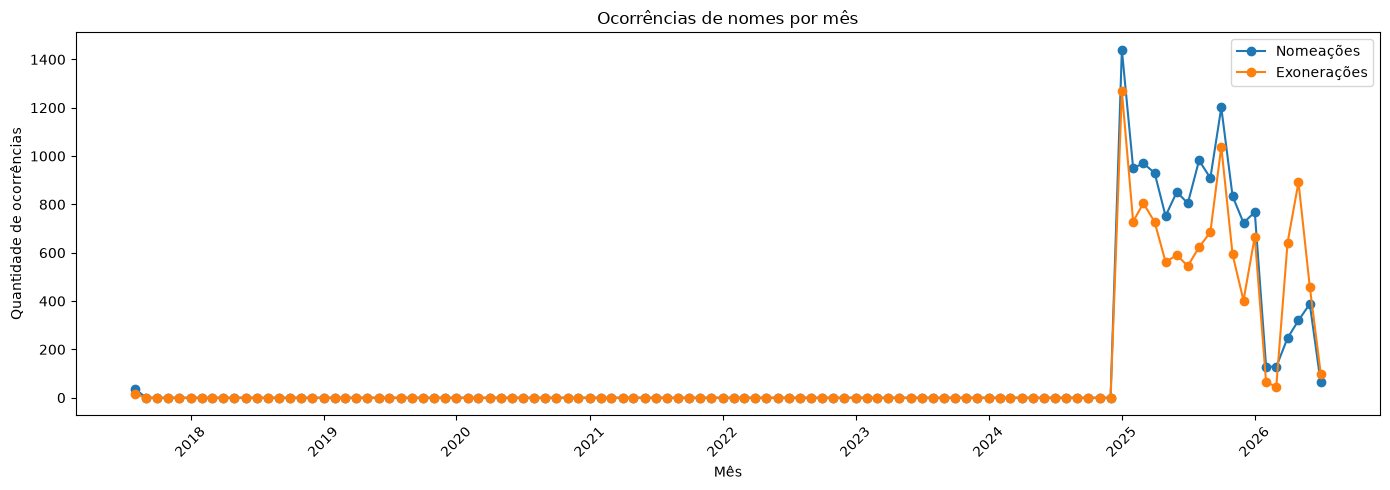

In [8]:
def serie_mensal(base):
    return (base.set_index("dataPubli")
            .resample("MS")
            .size()
            .rename("ocorrencias")
            .reset_index())

mensal_nom = serie_mensal(nomeados)
mensal_exo = serie_mensal(exonerados)

plt.figure(figsize=(14, 5))
plt.plot(mensal_nom["dataPubli"], mensal_nom["ocorrencias"], marker="o", label="Nomeações")
plt.plot(mensal_exo["dataPubli"], mensal_exo["ocorrencias"], marker="o", label="Exonerações")
plt.title("Ocorrências de nomes por mês")
plt.xlabel("Mês")
plt.ylabel("Quantidade de ocorrências")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


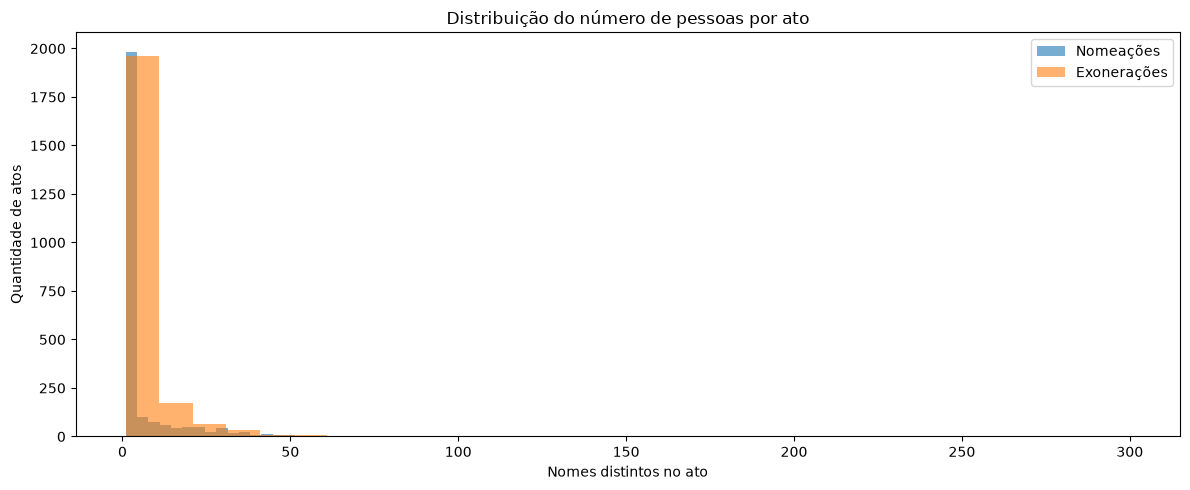

In [9]:
# Distribuição do número de nomes por ato
qtd_nom_ato = nomeados.groupby("id")["nome_normalizado"].nunique()
qtd_exo_ato = exonerados.groupby("id")["nome_normalizado"].nunique()

plt.figure(figsize=(12, 5))
plt.hist(qtd_nom_ato, bins=30, alpha=0.6, label="Nomeações")
plt.hist(qtd_exo_ato, bins=30, alpha=0.6, label="Exonerações")
plt.title("Distribuição do número de pessoas por ato")
plt.xlabel("Nomes distintos no ato")
plt.ylabel("Quantidade de atos")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Comparação: nomes em comum

A comparação principal usa `nome_normalizado`, portanto:
- `JOÃO DA SILVA` e `João da Silva` são considerados iguais;
- diferenças de acentuação não impedem a correspondência;
- pontuação não interfere.

Isso permite separar:
1. pessoas que aparecem **nas duas bases**;
2. pessoas exclusivas da base de nomeações;
3. pessoas exclusivas da base de exonerações.

A coincidência do nome, entretanto, não prova por si só que seja a mesma pessoa quando existem homônimos.


In [17]:
set_nom = set(nomeados["nome_normalizado"].dropna())
set_exo = set(exonerados["nome_normalizado"].dropna())

comuns = sorted(set_nom & set_exo)
so_nomeados = sorted(set_nom - set_exo)
so_exonerados = sorted(set_exo - set_nom)

print(f"Nomes distintos em comum: {len(comuns):,}")
print(f"Exclusivos de nomeações: {len(so_nomeados):,}")
print(f"Exclusivos de exonerações: {len(so_exonerados):,}")

comparacao = (freq_nom.join(freq_exo, how="outer")
              .fillna({"ocorrencias_nomeacao": 0, "atos_nomeacao": 0,
                       "ocorrencias_exoneracao": 0, "atos_exoneracao": 0})
              .reset_index())

comparacao["aparece_nas_duas"] = (
    (comparacao["ocorrencias_nomeacao"] > 0) &
    (comparacao["ocorrencias_exoneracao"] > 0)
)

print("\nPessoas que aparecem nas duas bases — 50 primeiras por ocorrências totais:")
comuns_df = comparacao[comparacao["aparece_nas_duas"]].copy()
comuns_df["total_ocorrencias"] = (
    comuns_df["ocorrencias_nomeacao"] + comuns_df["ocorrencias_exoneracao"]
)
display(comuns_df.sort_values("total_ocorrencias", ascending=False).head(10))


Nomes distintos em comum: 4,607
Exclusivos de nomeações: 7,138
Exclusivos de exonerações: 5,640

Pessoas que aparecem nas duas bases — 50 primeiras por ocorrências totais:


,nome_normalizado,ocorrencias_nomeacao,atos_nomeacao,primeira_nomeacao,ultima_nomeacao,ocorrencias_exoneracao,atos_exoneracao,primeira_exoneracao,ultima_exoneracao,aparece_nas_duas,total_ocorrencias
2686,CARGO COMISSIONADO QUE MENCIONA,12.0,12.0,2025-01-31,2025-08-13,1.0,1.0,2026-06-26,2026-06-26,True,13.0
12133,MAURICIO QUIRINO DE SOUZA,5.0,5.0,2025-01-23,2025-11-13,5.0,5.0,2025-02-12,2025-12-16,True,10.0
13005,PARA ACERTO DA VIDA FUNCIONAL,6.0,6.0,2025-05-06,2025-12-23,4.0,4.0,2025-05-05,2025-10-09,True,10.0
5600,FELIPE FERREIRA DE LIMA,5.0,5.0,2025-03-12,2026-06-02,5.0,5.0,2025-03-12,2026-05-25,True,10.0
6876,GUSTAVO REIS FERREIRA,5.0,5.0,2025-01-16,2025-11-12,5.0,5.0,2025-01-14,2025-11-04,True,10.0
7894,JOAO CLAUDIO WAGNER SILVA,5.0,5.0,2025-04-04,2026-01-26,5.0,5.0,2025-04-24,2026-01-26,True,10.0
14677,ROBSON JOSE STORANI,5.0,5.0,2025-01-16,2025-11-11,5.0,5.0,2025-01-16,2025-11-11,True,10.0
2962,CARLOS LEONARDO RAMOS POVOA,5.0,5.0,2025-08-14,2025-12-11,4.0,4.0,2025-09-12,2025-12-11,True,9.0
421,ALEX SANDER DA SILVA SURIANO,4.0,4.0,2025-01-29,2026-01-26,5.0,5.0,2025-01-29,2026-06-23,True,9.0
7522,JAIR DE SIQUEIRA BITTENCOURT JUNIOR,5.0,5.0,2025-02-26,2025-11-19,4.0,4.0,2025-03-11,2025-12-11,True,9.0


## 7. Datas de nomeação e exoneração

Para cada nome que aparece nas duas bases, calculamos:
- primeira publicação de nomeação;
- última publicação de nomeação;
- primeira publicação de exoneração;
- última publicação de exoneração;
- intervalo entre a primeira nomeação e a primeira exoneração.

O intervalo é uma **medida descritiva baseada nas datas de publicação dos atos**, não uma confirmação de duração efetiva do vínculo funcional.


In [16]:
trajetoria = (comparacao[comparacao["aparece_nas_duas"]].copy())

trajetoria["intervalo_primeira_nomeacao_exoneracao_dias"] = (
    pd.to_datetime(trajetoria["primeira_exoneracao"]) -
    pd.to_datetime(trajetoria["primeira_nomeacao"])
).dt.days

trajetoria = trajetoria.sort_values(
    ["primeira_nomeacao", "primeira_exoneracao", "nome_normalizado"]
)

display(trajetoria[[
    "nome_normalizado",
    "ocorrencias_nomeacao", "atos_nomeacao",
    "primeira_nomeacao", "ultima_nomeacao",
    "ocorrencias_exoneracao", "atos_exoneracao",
    "primeira_exoneracao", "ultima_exoneracao",
    "intervalo_primeira_nomeacao_exoneracao_dias"
]].head(10))

,nome_normalizado,ocorrencias_nomeacao,atos_nomeacao,primeira_nomeacao,ultima_nomeacao,ocorrencias_exoneracao,atos_exoneracao,primeira_exoneracao,ultima_exoneracao,intervalo_primeira_nomeacao_exoneracao_dias
2101,BEATRIZ GRECO GUIMARAES DO NASCIMENTO REIS,1.0,1.0,2017-08-30,2017-08-30,1.0,1.0,2017-08-30,2017-08-30,0
6587,GIOVANNI TORRES DIAS,4.0,4.0,2017-08-30,2026-06-02,2.0,2.0,2017-08-30,2025-03-12,0
9435,LEILA GELELETE BANDEIRA ANTUNES,1.0,1.0,2017-08-30,2017-08-30,1.0,1.0,2017-08-30,2017-08-30,0
11966,MARTA CORREA GOMES CHAVES,1.0,1.0,2017-08-30,2017-08-30,1.0,1.0,2017-08-30,2017-08-30,0
16920,VIVIAN MAIA REIS,1.0,1.0,2017-08-30,2017-08-30,1.0,1.0,2017-08-30,2017-08-30,0
695,ALINE DE LIMA SILVA,1.0,1.0,2025-01-02,2025-01-02,1.0,1.0,2025-01-02,2025-01-02,0
787,ALLANIS DIMITRIA DE OLIVEIRA E SOUZA PEDROSA,2.0,2.0,2025-01-02,2025-12-01,2.0,2.0,2025-01-02,2025-12-02,0
874,AMANDA DARZE RICHA,1.0,1.0,2025-01-02,2025-01-02,1.0,1.0,2025-01-02,2025-01-02,0
966,ANA CALINE BATISTA BORGES DUARTE,1.0,1.0,2025-01-02,2025-01-02,1.0,1.0,2025-01-02,2025-01-02,0
1761,ANNA WANESSA NOBREGA DOS SANTOS,2.0,2.0,2025-01-02,2026-04-14,1.0,1.0,2025-01-02,2025-01-02,0


In [15]:
# Casos com nomeação e exoneração na mesma data de publicação
mesma_data = trajetoria[
    trajetoria["intervalo_primeira_nomeacao_exoneracao_dias"] == 0
].copy()

print(f"Nomes com primeira nomeação e primeira exoneração na mesma data: {len(mesma_data):,}")
display(mesma_data[[
    "nome_normalizado",
    "primeira_nomeacao",
    "primeira_exoneracao",
    "ocorrencias_nomeacao",
    "ocorrencias_exoneracao"
]].head(10))

# Intervalos positivos/negativos
print("\nResumo do intervalo entre primeira nomeação e primeira exoneração:")
display(trajetoria["intervalo_primeira_nomeacao_exoneracao_dias"].describe())


Nomes com primeira nomeação e primeira exoneração na mesma data: 1,585


,nome_normalizado,primeira_nomeacao,primeira_exoneracao,ocorrencias_nomeacao,ocorrencias_exoneracao
2101,BEATRIZ GRECO GUIMARAES DO NASCIMENTO REIS,2017-08-30,2017-08-30,1.0,1.0
6587,GIOVANNI TORRES DIAS,2017-08-30,2017-08-30,4.0,2.0
9435,LEILA GELELETE BANDEIRA ANTUNES,2017-08-30,2017-08-30,1.0,1.0
11966,MARTA CORREA GOMES CHAVES,2017-08-30,2017-08-30,1.0,1.0
16920,VIVIAN MAIA REIS,2017-08-30,2017-08-30,1.0,1.0
695,ALINE DE LIMA SILVA,2025-01-02,2025-01-02,1.0,1.0
787,ALLANIS DIMITRIA DE OLIVEIRA E SOUZA PEDROSA,2025-01-02,2025-01-02,2.0,2.0
874,AMANDA DARZE RICHA,2025-01-02,2025-01-02,1.0,1.0
966,ANA CALINE BATISTA BORGES DUARTE,2025-01-02,2025-01-02,1.0,1.0
1761,ANNA WANESSA NOBREGA DOS SANTOS,2025-01-02,2025-01-02,2.0,1.0



Resumo do intervalo entre primeira nomeação e primeira exoneração:


count    4607.000000
mean       64.444975
std       135.474145
min      -507.000000
25%         0.000000
50%         0.000000
75%       132.000000
max       541.000000
Name: intervalo_primeira_nomeacao_exoneracao_dias, dtype: float64

## 8. Nomes recorrentes nas duas bases

A tabela abaixo destaca pessoas que têm múltiplas ocorrências nos dois conjuntos. Isso ajuda a identificar:
- recorrência de nomeações;
- recorrência de exonerações;
- pessoas que aparecem repetidamente em ambos os fluxos.


In [14]:
recorrentes_duas = trajetoria[
    (trajetoria["ocorrencias_nomeacao"] > 1) |
    (trajetoria["ocorrencias_exoneracao"] > 1)
].copy()

recorrentes_duas["total_ocorrencias"] = (
    recorrentes_duas["ocorrencias_nomeacao"] +
    recorrentes_duas["ocorrencias_exoneracao"]
)

display(
    recorrentes_duas.sort_values(
        ["total_ocorrencias", "nome_normalizado"], ascending=[False, True]
    )[[
        "nome_normalizado",
        "ocorrencias_nomeacao", "atos_nomeacao",
        "ocorrencias_exoneracao", "atos_exoneracao",
        "primeira_nomeacao", "ultima_nomeacao",
        "primeira_exoneracao", "ultima_exoneracao",
        "intervalo_primeira_nomeacao_exoneracao_dias"
    ]].head(10)
)

,nome_normalizado,ocorrencias_nomeacao,atos_nomeacao,ocorrencias_exoneracao,atos_exoneracao,primeira_nomeacao,ultima_nomeacao,primeira_exoneracao,ultima_exoneracao,intervalo_primeira_nomeacao_exoneracao_dias
2686,CARGO COMISSIONADO QUE MENCIONA,12.0,12.0,1.0,1.0,2025-01-31,2025-08-13,2026-06-26,2026-06-26,511
5600,FELIPE FERREIRA DE LIMA,5.0,5.0,5.0,5.0,2025-03-12,2026-06-02,2025-03-12,2026-05-25,0
6876,GUSTAVO REIS FERREIRA,5.0,5.0,5.0,5.0,2025-01-16,2025-11-12,2025-01-14,2025-11-04,-2
7894,JOAO CLAUDIO WAGNER SILVA,5.0,5.0,5.0,5.0,2025-04-04,2026-01-26,2025-04-24,2026-01-26,20
12133,MAURICIO QUIRINO DE SOUZA,5.0,5.0,5.0,5.0,2025-01-23,2025-11-13,2025-02-12,2025-12-16,20
13005,PARA ACERTO DA VIDA FUNCIONAL,6.0,6.0,4.0,4.0,2025-05-06,2025-12-23,2025-05-05,2025-10-09,-1
14677,ROBSON JOSE STORANI,5.0,5.0,5.0,5.0,2025-01-16,2025-11-11,2025-01-16,2025-11-11,0
421,ALEX SANDER DA SILVA SURIANO,4.0,4.0,5.0,5.0,2025-01-29,2026-01-26,2025-01-29,2026-06-23,0
2962,CARLOS LEONARDO RAMOS POVOA,5.0,5.0,4.0,4.0,2025-08-14,2025-12-11,2025-09-12,2025-12-11,29
7522,JAIR DE SIQUEIRA BITTENCOURT JUNIOR,5.0,5.0,4.0,4.0,2025-02-26,2025-11-19,2025-03-11,2025-12-11,13


## 9. Auditoria da limpeza

Como a extração original é baseada em texto, esta seção mantém uma visão dos registros que merecem revisão manual.

O objetivo é **não esconder incertezas da extração**: nomes muito curtos, resíduos administrativos ou segmentos atípicos podem ser falsos positivos. A limpeza melhora a base analítica, mas não substitui a conferência do ato original.


In [ ]:
# Heurísticas simples para apontar itens que merecem inspeção.
def itens_suspeitos(base):
    s = base["nome_original"].astype(str)
    mascara = (
        s.str.len().lt(5) |
        s.str.contains(r"\b(?:CEL|PM|RG|EMPREGADO|NOMEIA|CARGO|LIQUIDANTE|CTC)\b",
                       case=False, regex=True)
    )
    return base[mascara].sort_values(["nome_original", "dataPubli"])

print("Itens suspeitos — nomeações:")
display(itens_suspeitos(nomeados).head(100))

print("Itens suspeitos — exonerações:")
display(itens_suspeitos(exonerados).head(100))

Itens suspeitos — nomeações:


,id,dataPubli,nome_original,nome_normalizado,tipo
1473,2623923,2025-01-31,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
4326,2643238,2025-05-05,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
4402,2643247,2025-05-05,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
4674,2645469,2025-05-13,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
5053,2650469,2025-05-29,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
5289,2651458,2025-06-04,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
5915,2657382,2025-06-27,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
6168,2659355,2025-07-08,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
6965,2667592,2025-08-06,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação
7031,2668152,2025-08-07,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Nomeação


Itens suspeitos — exonerações:


,id,dataPubli,nome_original,nome_normalizado,tipo
11272,2744578,2026-06-26,CARGO COMISSIONADO QUE MENCIONA,CARGO COMISSIONADO QUE MENCIONA,Exoneração
5431,2667420,2025-08-07,NOMEIA NO ÂMBITO DA EMPRESA DE ASSISTÊNCIA TÉCNICA E EXTENSÃO RURAL DO ESTADO DO RIO DE JANEIRO,NOMEIA NO AMBITO DA EMPRESA DE ASSISTENCIA TECNICA E EXTENSAO RURAL DO ESTADO DO RIO DE JANEIRO,Exoneração
6856,2684453,2025-10-07,NOMEIA NO ÂMBITO DA EMPRESA DE ASSISTÊNCIA TÉCNICA E EXTENSÃO RURAL DO ESTADO DO RIO DE JANEIRO,NOMEIA NO AMBITO DA EMPRESA DE ASSISTENCIA TECNICA E EXTENSAO RURAL DO ESTADO DO RIO DE JANEIRO,Exoneração
7409,2687691,2025-10-21,NOMEIA NO ÂMBITO DA EMPRESA DE ASSISTÊNCIA TÉCNICA E EXTENSÃO RURAL DO ESTADO DO RIO DE JANEIRO,NOMEIA NO AMBITO DA EMPRESA DE ASSISTENCIA TECNICA E EXTENSAO RURAL DO ESTADO DO RIO DE JANEIRO,Exoneração
7411,2687692,2025-10-21,NOMEIA NO ÂMBITO DA EMPRESA DE ASSISTÊNCIA TÉCNICA E EXTENSÃO RURAL DO ESTADO DO RIO DE JANEIRO,NOMEIA NO AMBITO DA EMPRESA DE ASSISTENCIA TECNICA E EXTENSAO RURAL DO ESTADO DO RIO DE JANEIRO,Exoneração


## 10. Exportação das bases tratadas

São geradas duas bases analíticas:
- uma linha por nomeação;
- uma linha por exoneração.

Também é exportada uma tabela de comparação das pessoas presentes nas duas bases, incluindo as datas e o intervalo entre os primeiros atos.


In [ ]:
nomeados.to_csv("analise_nomeados_limpos.csv", index=False, encoding="utf-8-sig")
exonerados.to_csv("analise_exonerados_limpos.csv", index=False, encoding="utf-8-sig")
comparacao.to_csv("comparacao_nomes_nomeacao_exoneracao.csv", index=False, encoding="utf-8-sig")
trajetoria.to_csv("trajetoria_nomes_comuns.csv", index=False, encoding="utf-8-sig")

print("Arquivos exportados:")
for arq in [
    "analise_nomeados_limpos.csv",
    "analise_exonerados_limpos.csv",
    "comparacao_nomes_nomeacao_exoneracao.csv",
    "trajetoria_nomes_comuns.csv",
]:
    print(" -", arq)

Arquivos exportados:
 - analise_nomeados_limpos.csv
 - analise_exonerados_limpos.csv
 - comparacao_nomes_nomeacao_exoneracao.csv
 - trajetoria_nomes_comuns.csv
